# Module 3 — Task 2: Supervised fraud model

**Business problem (brief, verbatim):**
> NovaFin processes thousands of transactions every day. Management wants to identify suspicious transactions while minimizing unnecessary investigation.

**Task 2 (brief, verbatim):**
> **Task 2 — Supervised fraud model.** Target: Fraud_Flag. Build model and compare performance

"Supervised" = the model learns from past transactions whose answer (fraud or not) is known.

**Where this task sits:** data and what drives fraud (Task 1) → **supervised fraud model (this task)** → anomaly detection with Isolation Forest (Task 3) → cost-based threshold (Task 4).

**What the brief asks and what it doesn't:** build a model and compare performance. It doesn't ask for a fraud / not-fraud label: turning a score into "investigate" needs a threshold, which is Task 4. So performance here is shown at **every investigation budget** (the share of transactions investigated), not at one cut-off.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Load, split by time, and the leakage checks |
| 2 | The inputs: two sets |
| 3 | The models, simplest to most complex, and the benchmark (amount alone) |
| 4 | 25 rounds of cross-validation on the training transactions |
| 5 | Overfitting check |
| 6 | Choosing the model: the agreed rule, step by step |
| 7 | The finance case: frauds and ₹ caught at each investigation budget |
| 8 | The final test: 6,000 later transactions, used once |
| 9 | Calibration: are the probabilities right? (reported) |
| 10 | Explaining the model |
| 11 | What the results say |
| 12 | Save the outputs, including each transaction's score for Tasks 3 and 4 |

**Decisions used** (in `docs/decisions.md`): M3-01 split · M3-02 measures · M3-11 inputs · M3-12 models and the selection rule · M3-13 calibration · M3-14 hand-off, explainability, leakage checks, finance case.

## 0. Setup

Works locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.
- Takes about 11 minutes: 11 model set-ups × 25 rounds, some tuned inside each round.

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_03_fraud_detection"
OUT_DIR = MODULE_DIR / "outputs" / "task2"            # tables, charts, scores for Tasks 3 and 4
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))       # make the Module 3 helpers importable

warnings.filterwarnings("ignore")
os.environ["LOKY_MAX_CPU_COUNT"] = "4"                # avoids a harmless Windows CPU-count warning

# ---- Libraries ---------------------------------------------------------------------------
import numpy as np                    # maths on arrays
import pandas as pd                   # tables
import matplotlib.pyplot as plt       # charts
import joblib                         # save the fitted model
from scipy import stats               # t-distribution for the paired ranges
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, accuracy_score
from lightgbm import LGBMClassifier
import shap                           # explaining each prediction

# ---- Module 3 helpers --------------------------------------------------------------------
from m03_data import load_transactions, add_features, make_inputs, INPUT_SETS
from m03_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, FRAUD, NORMAL
apply_style()
plt.close("all")                      # start clean when run from the module runner

SEED = 42                             # one fixed random seed everywhere (project decision P-06)
LAKH, CRORE = 1e5, 1e7
GAP_LIMIT = 0.10                      # decision M3-12: average training-vs-unseen ROC-AUC gap that rules a model out
BUDGETS = [0.01, 0.05, 0.10]          # reading points on the catch curves (not pass lines, decision M3-02)
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str, keep_index: bool = False) -> None:
    """Save a table to outputs/task2/<name>.csv."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=keep_index)


def save_chart(fig, name: str) -> None:
    """Save a chart to outputs/task2/<name>.png at print quality."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Project folder found")
print("Outputs go to: ", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Project folder found
Outputs go to:  module_03_fraud_detection/outputs/task2


## 1. Load, split by time, and the leakage checks (decisions M3-01, M3-14)

**Split by time:** the model learns from the first 80% of transactions and is tested once, at the end, on the last 20%. That is how it would be used: scoring *future* transactions. Task 1 found fraud stable over time, so learning from the past costs nothing.

**Leakage** = an input that secretly contains the answer, or information not available when the transaction happens. A model with leakage looks excellent in testing and fails in real use. Four checks:

| Check | Why |
| --- | --- |
| Fraud_Flag is in no input | The answer must never be an input |
| Every training transaction happens before every test transaction | The test must be "the future" |
| Device and location change use only the customer's **earlier** transaction | A customer's first transaction must show "no change" |
| Historical_Avg_Transaction doesn't include the current amount | If it did, the amount ratio would contain part of the current transaction. If included, large transactions would push the "usual" amount up, so the two would be clearly positively related |

In [2]:
tx = add_features(load_transactions())                 # 30,000 rows in time order, with the derived columns
cut = int(0.8 * len(tx))
train, test = tx.iloc[:cut].reset_index(drop=True), tx.iloc[cut:].reset_index(drop=True)
y_train, y_test = train.Fraud_Flag.to_numpy(), test.Fraud_Flag.to_numpy()

split = pd.DataFrame({name: {"Transactions": len(t), "Frauds": int(t.Fraud_Flag.sum()), "Fraud rate": t.Fraud_Flag.mean(),
                             "From": str(t.Timestamp.min().date()), "To": str(t.Timestamp.max().date()),
                             "₹ in fraud (crore)": t.Amount[t.Fraud_Flag == 1].sum() / CRORE}
                      for name, t in [("Training", train), ("Test", test)]}).T
display(split)

# ---- Leakage checks ----------------------------------------------------------------------
checks = {}
checks["Fraud_Flag in no input"] = all("Fraud_Flag" not in cols for cols in INPUT_SETS.values())
checks["All training before all test"] = bool(train.Timestamp.max() <= test.Timestamp.min())
first = tx.groupby("Customer_ID").cumcount() == 0
checks["First transaction of each customer shows no change"] = bool(
    (tx.loc[first, "Device_Change"] == 0).all() and (tx.loc[first, "Location_Change"] == 0).all())
r_all = np.corrcoef(np.log(tx.Amount), np.log(tx.Historical_Avg_Transaction))[0, 1]
fr = tx[tx.Fraud_Flag == 1]
r_fraud = np.corrcoef(np.log(fr.Amount), np.log(fr.Historical_Avg_Transaction))[0, 1]
checks[f"Usual amount unrelated to current amount (correlation {r_all:+.3f}; frauds {r_fraud:+.3f})"] = bool(abs(r_all) < 0.05 and r_fraud < 0.05)
for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(checks.values()), "A leakage check failed"

,Transactions,Frauds,Fraud rate,From,To,₹ in fraud (crore)
Training,24000,540,0.0225,2025-01-01,2026-05-01,1.610147
Test,6000,144,0.024,2026-05-01,2026-08-31,0.399423


PASS  Fraud_Flag in no input
PASS  All training before all test
PASS  First transaction of each customer shows no change
PASS  Usual amount unrelated to current amount (correlation +0.003; frauds -0.055)


## 2. The inputs: two sets (decision M3-11)

| Set | Columns | Why |
| --- | --- | --- |
| **Strong + weak** | Amount, Amount_Ratio, Historical_Avg_Transaction, Transaction_Type | Task 1's strong and weak columns |
| **All columns** | The above, plus Merchant_Category, Location, Account_Age_Months, Transaction_Frequency, Hour, Weekday, Device_Change, Location_Change | Every column known at transaction time: one that is uninformative alone may help in combination |

`make_inputs()` (helper) turns them into numbers:
```text
Amount, Amount_Ratio, Historical_Avg_Transaction → ln(x)      money is skewed; ln keeps the order and evens the spacing
Label columns → one 0/1 column per value except the first (one-hot)
```
Note: ln(Amount_Ratio) = ln(Amount) − ln(Historical_Avg_Transaction), so the three money inputs carry two pieces of information. Logistic regression's small built-in penalty and lasso cope with that; trees are unaffected.

Customer_ID, Device_ID and Transaction_ID are never inputs: they are labels, and Task 1 found no usable signal in them.

**Rule (M3-11):** the simpler set wins unless more inputs raise PR-AUC beyond chance.

In [3]:
X_train = {name: make_inputs(train, cols) for name, cols in INPUT_SETS.items()}
X_test = {name: make_inputs(test, cols) for name, cols in INPUT_SETS.items()}
for name, X in X_train.items():
    assert list(X.columns) == list(X_test[name].columns)          # same columns in training and test
    print(f"{name:<14} {X.shape[1]:>2} inputs: {', '.join(X.columns)}")

Strong + weak   5 inputs: ln_Amount, ln_Amount_Ratio, ln_Historical_Avg_Transaction, Transaction_Type_Transfer, Transaction_Type_Withdrawal
All columns    28 inputs: ln_Amount, ln_Amount_Ratio, ln_Historical_Avg_Transaction, Transaction_Type_Transfer, Transaction_Type_Withdrawal, Merchant_Category_Investment, Merchant_Category_Online, Merchant_Category_Other, Merchant_Category_Retail, Merchant_Category_Travel, Merchant_Category_Utilities, Location_Chennai, Location_Delhi, Location_Hyderabad, Location_Kolkata, Location_Mumbai, Location_Pune, Account_Age_Months, Transaction_Frequency, Hour, Weekday_Tuesday, Weekday_Wednesday, Weekday_Thursday, Weekday_Friday, Weekday_Saturday, Weekday_Sunday, Device_Change, Location_Change


## 3. The models and the benchmark (decision M3-12)

Simplest to most complex. The selection rule prefers the simpler model when two are equally good.

| # | Model | What it is | Settings |
| --- | --- | --- | --- |
| 0 | **Amount alone** (benchmark) | Rank by amount, the bank's simplest rule. Turned into a probability by a one-input logistic regression on ln(Amount), so its probabilities can be compared too | — |
| 1 | Logistic regression | A weighted sum of inputs turned into a probability | Small built-in penalty (C = 1) |
| 2 | Lasso | Logistic regression whose penalty can switch inputs off | Penalty tuned inside each round (inner 3-fold CV, by PR-AUC) |
| 3 | Decision tree | A flowchart of yes/no questions | Depth 2–6 tuned inside each round; at least 50 transactions per end box |
| 4 | Random forest | 200 trees on random samples, averaged | Depth ≤ 8; at least 20 transactions per end box |
| 5 | LightGBM | Trees built one after another, each fixing the last one's errors | Kept light: learning rate 0.05; tree size (4 or 8 leaves) and number of trees (100 or 300) tuned inside each round; at least 50 transactions per leaf |

```text
Logistic:  P(fraud) = 1 ÷ (1 + e^−(b0 + b1·x1 + … + bk·xk))
Lasso:     same, choosing b to minimise  log loss + λ × (|b1| + … + |bk|)   (λ large → more inputs switched off)
```

**No class weights** (M3-12): they leave the ranking unchanged and inflate every probability (average P(fraud) from 2.3% to 27–37%), which Task 4 can't use.

In [4]:
INNER = StratifiedKFold(3, shuffle=True, random_state=SEED)       # inner CV for tuning, inside each round


def make_model(name: str):
    """A fresh, unfitted model (Pipeline) for one of the six set-ups."""
    if name == "Amount alone":
        return Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=2000))])
    if name == "Logistic":
        return Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(C=1.0, max_iter=5000))])
    if name == "Lasso":
        return Pipeline([("scale", StandardScaler()),
                         ("model", LogisticRegressionCV(Cs=10, penalty="l1", solver="liblinear", cv=INNER,
                                                        scoring="average_precision", max_iter=5000,
                                                        random_state=SEED))])
    if name == "Decision tree":
        return GridSearchCV(DecisionTreeClassifier(min_samples_leaf=50, random_state=SEED),
                            {"max_depth": [2, 3, 4, 5, 6]}, cv=INNER, scoring="average_precision")
    if name == "Random forest":
        return RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=20, random_state=SEED, n_jobs=4)
    if name == "LightGBM":
        return GridSearchCV(LGBMClassifier(learning_rate=0.05, min_child_samples=50, subsample=0.8, subsample_freq=1,
                                           colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=4),
                            {"num_leaves": [4, 8], "n_estimators": [100, 300]}, cv=INNER, scoring="average_precision")
    raise ValueError(name)


MODELS = ["Amount alone", "Logistic", "Lasso", "Decision tree", "Random forest", "LightGBM"]
COMPLEXITY = {m: i for i, m in enumerate(MODELS)}                     # 0 = simplest
SET_COMPLEXITY = {"Strong + weak": 0, "All columns": 1}
# Every set-up compared: the benchmark uses ln(Amount) only; the five models use each input set.
SETUPS = [("Amount alone", "Amount only")] + [(m, s) for m in MODELS[1:] for s in INPUT_SETS]
print(len(SETUPS), "set-ups:", ", ".join(f"{m} [{s}]" for m, s in SETUPS))

11 set-ups: Amount alone [Amount only], Logistic [Strong + weak], Logistic [All columns], Lasso [Strong + weak], Lasso [All columns], Decision tree [Strong + weak], Decision tree [All columns], Random forest [Strong + weak], Random forest [All columns], LightGBM [Strong + weak], LightGBM [All columns]


## 4. 25 rounds of cross-validation on the training transactions (decisions M3-01, M3-02)

```text
24,000 training transactions → 5 parts of 4,800 (each keeps the 2.3% fraud share)
Each round: train on 4 parts, score the 5th (transactions it never saw)
5 rounds × 5 different shuffles = 25 scores per set-up, all set-ups on the same 25 splits
```

Each round also records the ROC-AUC on the transactions the model learned from (for the overfitting check), and the share of frauds and of fraud ₹ caught when the top 1%, 5% or 10% are investigated.

**Out-of-fold score:** each training transaction is scored once per shuffle by a model that didn't see it; the average of those 5 scores is its honest score, used for the finance case and handed to Tasks 3 and 4.

In [5]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
SPLITS = list(cv.split(X_train["All columns"], y_train))
amount_train = train.Amount.to_numpy()
X_amount_train = np.log(train[["Amount"]].to_numpy())          # benchmark input: ln(Amount)
X_amount_test = np.log(test[["Amount"]].to_numpy())


def catch(scores, y, amount, share):
    """Investigate the top `share` of transactions by score: share of frauds and of fraud ₹ caught, and precision."""
    k = max(1, int(round(share * len(scores))))
    top = np.argsort(-scores, kind="stable")[:k]
    return {"recall": y[top].sum() / y.sum(), "rupees": (amount[top] * y[top]).sum() / (amount * y).sum(),
            "precision": y[top].mean()}


def inputs_for(setup_set: str, idx, train_side: bool = True):
    """Rows `idx` of the input table for a set-up (benchmark uses ln(Amount) only)."""
    if setup_set == "Amount only":
        return X_amount_train[idx]
    return X_train[setup_set].iloc[idx]


rows, OOF = [], {}
for m, s in SETUPS:
    t0 = time.time()
    oof = np.zeros(len(y_train))
    for r, (a, b) in enumerate(SPLITS, start=1):
        model = make_model(m).fit(inputs_for(s, a), y_train[a])
        p = model.predict_proba(inputs_for(s, b))[:, 1]             # transactions this round never saw
        p_fit = model.predict_proba(inputs_for(s, a))[:, 1]         # transactions it learned from
        oof[b] += p
        row = {"Model": m, "Inputs": s, "Round": r, "PR_AUC": average_precision_score(y_train[b], p),
               "ROC_AUC": roc_auc_score(y_train[b], p), "Train_ROC_AUC": roc_auc_score(y_train[a], p_fit),
               "Brier": brier_score_loss(y_train[b], p), "Average_P": p.mean()}
        for share in BUDGETS:
            c = catch(p, y_train[b], amount_train[b], share)
            row[f"Recall@{share:.0%}"], row[f"Rupees@{share:.0%}"] = c["recall"], c["rupees"]
        rows.append(row)
    OOF[(m, s)] = oof / 5                                           # each transaction scored once per shuffle
    g = pd.DataFrame(rows[-len(SPLITS):])
    print(f"{m:<14} [{s:<13}] {time.time() - t0:5.0f}s | PR-AUC {g.PR_AUC.mean():.4f} | ROC-AUC {g.ROC_AUC.mean():.3f} | "
          f"gap {(g.Train_ROC_AUC - g.ROC_AUC).mean():+.3f}", flush=True)
cv_rounds = pd.DataFrame(rows)

Amount alone   [Amount only  ]     1s | PR-AUC 0.1158 | ROC-AUC 0.788 | gap +0.000


Logistic       [Strong + weak]     1s | PR-AUC 0.1266 | ROC-AUC 0.801 | gap +0.001


Logistic       [All columns  ]     2s | PR-AUC 0.1261 | ROC-AUC 0.796 | gap +0.009


Lasso          [Strong + weak]   141s | PR-AUC 0.1262 | ROC-AUC 0.801 | gap +0.001


Lasso          [All columns  ]   308s | PR-AUC 0.1248 | ROC-AUC 0.799 | gap +0.004


Decision tree  [Strong + weak]    14s | PR-AUC 0.1079 | ROC-AUC 0.790 | gap +0.029


Decision tree  [All columns  ]    23s | PR-AUC 0.1144 | ROC-AUC 0.784 | gap +0.039


Random forest  [Strong + weak]    61s | PR-AUC 0.1243 | ROC-AUC 0.779 | gap +0.140


Random forest  [All columns  ]    61s | PR-AUC 0.1336 | ROC-AUC 0.790 | gap +0.130


LightGBM       [Strong + weak]    57s | PR-AUC 0.1318 | ROC-AUC 0.794 | gap +0.056


LightGBM       [All columns  ]    74s | PR-AUC 0.1354 | ROC-AUC 0.793 | gap +0.075


In [6]:
# Summary over the 25 rounds: mean and standard deviation (how much a score depends on luck).
cv_rounds["Gap"] = cv_rounds.Train_ROC_AUC - cv_rounds.ROC_AUC
summary = cv_rounds.groupby(["Model", "Inputs"], sort=False).agg(
    PR_AUC=("PR_AUC", "mean"), PR_AUC_sd=("PR_AUC", "std"), ROC_AUC=("ROC_AUC", "mean"),
    Brier=("Brier", "mean"), Average_P=("Average_P", "mean"), Gap=("Gap", "mean"),
    **{f"Recall@{s:.0%}": (f"Recall@{s:.0%}", "mean") for s in BUDGETS},
    **{f"Rupees@{s:.0%}": (f"Rupees@{s:.0%}", "mean") for s in BUDGETS})
save_table(summary.round(5).reset_index(), "cv_summary")
summary.style.format({"PR_AUC": "{:.4f}", "PR_AUC_sd": "{:.4f}", "ROC_AUC": "{:.3f}", "Brier": "{:.5f}",
                      "Average_P": "{:.2%}", "Gap": "{:+.3f}"} |
                     {c: "{:.1%}" for c in summary.columns if "@" in c})

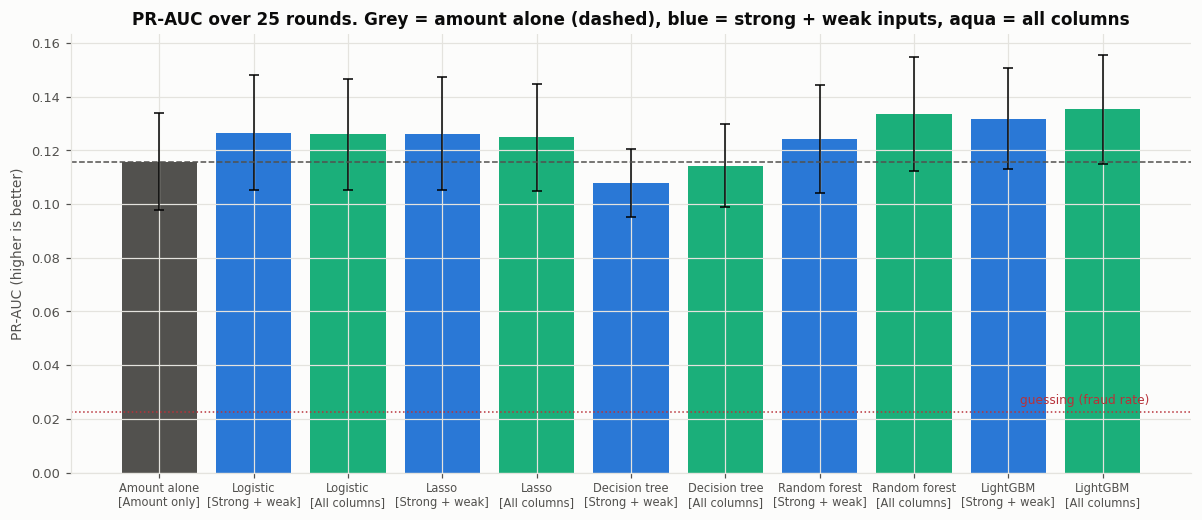

In [7]:
# Chart: PR-AUC of every set-up over the 25 rounds (mean ± 1 standard deviation).
fig, ax = plt.subplots(figsize=(11, 4.8))
labels = [f"{m}\n[{s}]" for m, s in summary.index]
x = np.arange(len(summary))
colours = [INK_2 if m == "Amount alone" else (BLUE if s == "Strong + weak" else AQUA) for m, s in summary.index]
ax.bar(x, summary.PR_AUC, yerr=summary.PR_AUC_sd, color=colours, capsize=3, error_kw={"lw": 1})
ax.axhline(summary.loc[("Amount alone", "Amount only"), "PR_AUC"], color=INK_2, ls="--", lw=1)
ax.axhline(y_train.mean(), color=FRAUD, ls=":", lw=1)
ax.text(len(x) - 0.5, y_train.mean() + 0.003, "guessing (fraud rate)", ha="right", fontsize=8, color=FRAUD)
ax.set_xticks(x, labels, fontsize=7.5); ax.set_ylabel("PR-AUC (higher is better)")
ax.set_title("PR-AUC over 25 rounds. Grey = amount alone (dashed), blue = strong + weak inputs, aqua = all columns")
fig.tight_layout(); save_chart(fig, "01_cv_comparison"); plt.show()

## 5. Overfitting check (decision M3-12)

```text
Gap = ROC-AUC on the transactions the model learned from − ROC-AUC on transactions it never saw
```
A big gap means the model memorises its training transactions instead of learning patterns that carry over. **A set-up is ruled out if its average gap over 25 rounds is above 0.10.**

Why 0.10 (agreed before results): with about 110 frauds per round, a single round's gap is noisy. Even logistic regression, which can barely memorise, showed single-round gaps up to about +0.08. A 0.05 line would sit inside that noise.

Ruled out: Random forest [Strong + weak], Random forest [All columns]


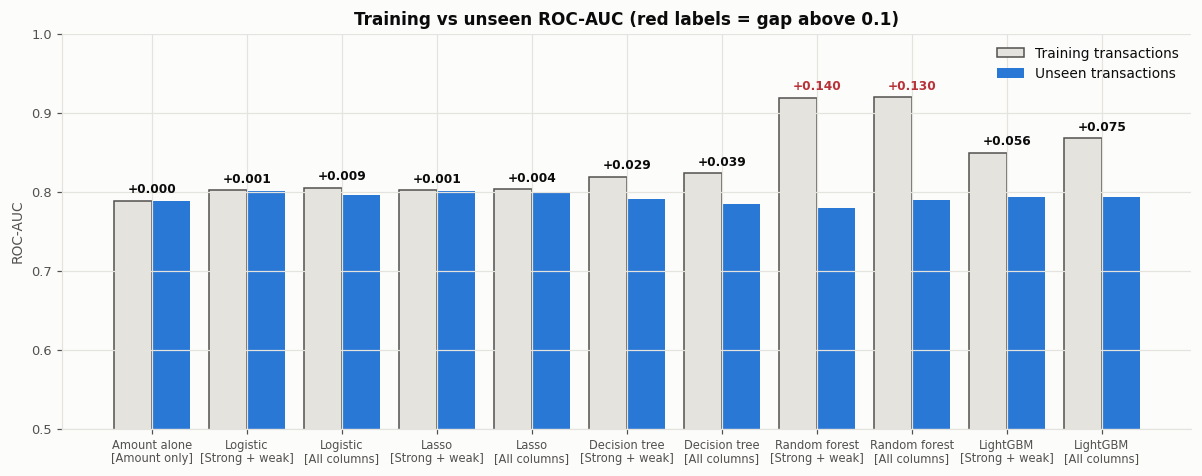

In [8]:
gap_tbl = cv_rounds.groupby(["Model", "Inputs"], sort=False).agg(
    Train=("Train_ROC_AUC", "mean"), Unseen=("ROC_AUC", "mean"), Gap=("Gap", "mean"),
    Lowest_round_gap=("Gap", "min"), Highest_round_gap=("Gap", "max"))
gap_tbl["Verdict"] = np.where(gap_tbl.Gap > GAP_LIMIT, "Ruled out: overfits", "Kept")
RULED_OUT = [k for k, v in gap_tbl.Verdict.items() if v != "Kept"]
print("Ruled out:", ", ".join(f"{m} [{s}]" for m, s in RULED_OUT) or "none")

fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(len(gap_tbl))
ax.bar(x - 0.2, gap_tbl.Train, 0.4, color=GRID, edgecolor=INK_2, label="Training transactions")
ax.bar(x + 0.2, gap_tbl.Unseen, 0.4, color=BLUE, label="Unseen transactions")
for i, (g, v) in enumerate(zip(gap_tbl.Gap, gap_tbl.Verdict)):
    ax.text(i, max(gap_tbl.Train.iloc[i], gap_tbl.Unseen.iloc[i]) + 0.01, f"{g:+.3f}", ha="center", fontsize=8,
            color=FRAUD if v != "Kept" else INK, fontweight="bold")
ax.set_xticks(x, [f"{m}\n[{s}]" for m, s in gap_tbl.index], fontsize=7.5); ax.set_ylim(0.5, 1.0)
ax.set_ylabel("ROC-AUC"); ax.legend(frameon=False)
ax.set_title(f"Training vs unseen ROC-AUC (red labels = gap above {GAP_LIMIT})")
fig.tight_layout(); save_chart(fig, "02_overfitting_check"); plt.show()
gap_tbl.style.format({"Train": "{:.3f}", "Unseen": "{:.3f}", "Gap": "{:+.3f}", "Lowest_round_gap": "{:+.3f}",
                      "Highest_round_gap": "{:+.3f}"})

## 6. Choosing the model: the agreed rule, step by step (decision M3-12)

1. Rule out set-ups whose average gap is above 0.10 (step 5).
2. Rank the rest by PR-AUC over the 25 rounds.
3. **The simplest set-up wins when its PR-AUC is within chance of the best.** "Within chance" = the paired 95% range of (best − this set-up) over the 25 rounds includes 0. Simpler = earlier in the model list; for the same model, the strong + weak inputs are simpler than all columns (M3-11).
4. Amount alone counts as the simplest. If nothing beats it beyond chance, the answer is the amount rule.

```text
Paired difference per round:  d_r = PR-AUC(best, round r) − PR-AUC(set-up, round r)
95% range = mean(d) ± t × sd(d) ÷ √25,   t = 2.064 (24 degrees of freedom)
```
The rounds reuse the same transactions, so the range is a little too narrow; the final test (step 8) is the independent check.

In [9]:
T_CRIT = stats.t.ppf(0.975, df=len(SPLITS) - 1)
kept = summary.drop(index=RULED_OUT)
BEST = kept.PR_AUC.idxmax()
per_round = cv_rounds.set_index(["Model", "Inputs", "Round"]).PR_AUC

choice = []
for key in kept.index:
    d = per_round.loc[BEST].to_numpy() - per_round.loc[key].to_numpy()
    half = T_CRIT * d.std(ddof=1) / np.sqrt(len(d)) if d.std() > 0 else 0.0
    choice.append({"Model": key[0], "Inputs": key[1], "PR-AUC": kept.loc[key, "PR_AUC"],
                   "Best − this": d.mean(), "95% low": d.mean() - half, "95% high": d.mean() + half,
                   "Within chance of best": bool(d.mean() - half <= 0),
                   "Complexity": (COMPLEXITY[key[0]], SET_COMPLEXITY.get(key[1], 0))})
choice = pd.DataFrame(choice).sort_values("Complexity")
CHOSEN = tuple(choice[choice["Within chance of best"]].iloc[0][["Model", "Inputs"]])
choice["Chosen"] = [(m, s) == CHOSEN for m, s in zip(choice.Model, choice.Inputs)]
print(f"Best PR-AUC: {BEST[0]} [{BEST[1]}] = {kept.loc[BEST, 'PR_AUC']:.4f}")
print(f"CHOSEN (simplest within chance of the best): {CHOSEN[0]} [{CHOSEN[1]}]")

# Does the chosen model beat amount alone beyond chance?
bench = per_round.loc[("Amount alone", "Amount only")].to_numpy()
d = per_round.loc[CHOSEN].to_numpy() - bench
half = T_CRIT * d.std(ddof=1) / np.sqrt(len(d))
VS_BENCH = (d.mean(), d.mean() - half, d.mean() + half, int((d > 0).sum()))
print(f"Chosen vs amount alone: PR-AUC {VS_BENCH[0]:+.4f} (95% range {VS_BENCH[1]:+.4f} to {VS_BENCH[2]:+.4f}), "
      f"better in {VS_BENCH[3]} of 25 rounds")
choice.drop(columns="Complexity").style.format({"PR-AUC": "{:.4f}", "Best − this": "{:+.4f}", "95% low": "{:+.4f}",
                                                "95% high": "{:+.4f}"}).hide(axis="index")

Best PR-AUC: LightGBM [All columns] = 0.1354
CHOSEN (simplest within chance of the best): LightGBM [Strong + weak]
Chosen vs amount alone: PR-AUC +0.0160 (95% range +0.0098 to +0.0223), better in 22 of 25 rounds


Model,Inputs,PR-AUC,Best − this,95% low,95% high,Within chance of best,Chosen
Amount alone,Amount only,0.1158,+0.0196,+0.0134,+0.0257,False,False
Logistic,Strong + weak,0.1266,+0.0088,+0.0029,+0.0147,False,False
Logistic,All columns,0.1261,+0.0093,+0.0041,+0.0145,False,False
Lasso,Strong + weak,0.1262,+0.0092,+0.0032,+0.0151,False,False
Lasso,All columns,0.1248,+0.0106,+0.0051,+0.0160,False,False
Decision tree,Strong + weak,0.1079,+0.0275,+0.0217,+0.0333,False,False
Decision tree,All columns,0.1144,+0.0210,+0.0158,+0.0263,False,False
LightGBM,Strong + weak,0.1318,+0.0036,-0.0020,+0.0091,True,True
LightGBM,All columns,0.1354,+0.0000,+0.0000,+0.0000,True,False


## 7. The finance case: frauds and ₹ caught at each investigation budget (decisions M3-02, M3-14)

**Investigation budget** = the share of transactions the bank investigates, taking the highest-scored first. The ₹10,000 / ₹500 costs belong to Task 4, so this step uses **actual rupees**:

```text
Frauds caught   = frauds among the investigated ÷ all frauds
Fraud ₹ caught  = ₹ of the frauds investigated ÷ ₹ of all frauds
Precision       = share of investigations that find a fraud
₹ per investigation = fraud ₹ caught ÷ number of investigations
```

Rankings compared, on the out-of-fold scores of the 24,000 training transactions:
- the **chosen model**;
- **amount alone** (largest first);
- **random** investigation (what you'd catch with no rule at all: a budget of x% catches about x% of frauds);
- **chosen model × amount** = expected ₹ loss. Shown for information only: whether Task 4 uses it is decided there.

The figures are also shown **per 1,000 transactions**, so they scale to the bank's real daily volume (the file holds about 49 a day; the brief says thousands).

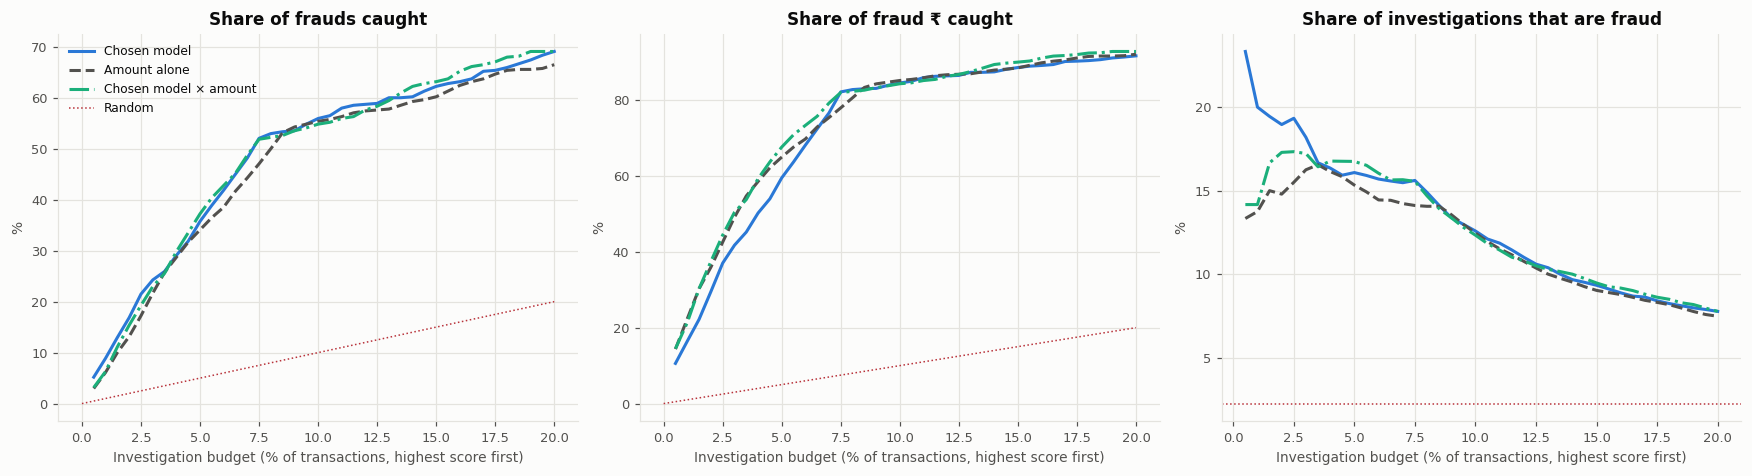

In [10]:
oof_chosen = OOF[CHOSEN]
oof_bench = OOF[("Amount alone", "Amount only")]
rankings = {"Chosen model": oof_chosen, "Amount alone": amount_train.astype(float),
            "Chosen model × amount": oof_chosen * amount_train}
shares = np.round(np.arange(0.005, 0.2001, 0.005), 3)
curve_rows = []
for name, score in rankings.items():
    for share in shares:
        c = catch(score, y_train, amount_train, share)
        n_inv = int(round(share * len(score)))
        curve_rows.append({"Ranking": name, "Budget": share, "Frauds caught": c["recall"], "Fraud ₹ caught": c["rupees"],
                           "Precision": c["precision"],
                           "₹ per investigation": c["rupees"] * (amount_train * y_train).sum() / n_inv})
curves = pd.DataFrame(curve_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
style = {"Chosen model": (BLUE, "-"), "Amount alone": (INK_2, "--"), "Chosen model × amount": (AQUA, "-.")}
for ax, col, title in [(axes[0], "Frauds caught", "Share of frauds caught"), (axes[1], "Fraud ₹ caught", "Share of fraud ₹ caught"),
                       (axes[2], "Precision", "Share of investigations that are fraud")]:
    for name, g in curves.groupby("Ranking", sort=False):
        ax.plot(g.Budget * 100, g[col] * 100, color=style[name][0], ls=style[name][1], lw=2, label=name)
    if col != "Precision":
        ax.plot([0, 20], [0, 20], color=FRAUD, ls=":", lw=1, label="Random")
    else:
        ax.axhline(y_train.mean() * 100, color=FRAUD, ls=":", lw=1, label="Random")
    ax.set_xlabel("Investigation budget (% of transactions, highest score first)"); ax.set_ylabel("%"); ax.set_title(title)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); save_chart(fig, "03_catch_curves"); plt.show()

In [11]:
# The model's extra catch over amount alone, round by round (25 rounds), at the reading-point budgets.
extra = []
for share in BUDGETS:
    for col, label in [(f"Recall@{share:.0%}", "Frauds caught"), (f"Rupees@{share:.0%}", "Fraud ₹ caught")]:
        a = cv_rounds.set_index(["Model", "Inputs", "Round"])[col]
        d = a.loc[CHOSEN].to_numpy() - a.loc[("Amount alone", "Amount only")].to_numpy()
        half = T_CRIT * d.std(ddof=1) / np.sqrt(len(d))
        extra.append({"Budget": f"{share:.0%}", "Measure": label, "Chosen": a.loc[CHOSEN].mean(),
                      "Amount alone": a.loc[("Amount alone", "Amount only")].mean(), "Difference": d.mean(),
                      "95% low": d.mean() - half, "95% high": d.mean() + half})
extra = pd.DataFrame(extra)

# Per 1,000 transactions, in ₹: what investigating x% delivers.
fraud_rupees_per_1000 = (amount_train * y_train).sum() / len(y_train) * 1000
per1000 = []
for share in BUDGETS:
    for name in rankings:
        r = curves[(curves.Ranking == name) & np.isclose(curves.Budget, share)].iloc[0]
        per1000.append({"Budget": f"{share:.0%}", "Ranking": name, "Investigations per 1,000": share * 1000,
                        "Frauds caught per 1,000": r["Frauds caught"] * y_train.mean() * 1000,
                        "Fraud ₹ caught per 1,000 (₹)": r["Fraud ₹ caught"] * fraud_rupees_per_1000,
                        "₹ per investigation": r["₹ per investigation"]})
per1000 = pd.DataFrame(per1000)
print(f"Fraud ₹ per 1,000 transactions (training period): ₹{fraud_rupees_per_1000:,.0f}")
display(extra.style.format({c: "{:+.1%}" if c in ("Difference", "95% low", "95% high") else "{:.1%}"
                            for c in ["Chosen", "Amount alone", "Difference", "95% low", "95% high"]}).hide(axis="index"))
per1000.style.format({"Investigations per 1,000": "{:.0f}", "Frauds caught per 1,000": "{:.1f}",
                      "Fraud ₹ caught per 1,000 (₹)": "₹{:,.0f}", "₹ per investigation": "₹{:,.0f}"}).hide(axis="index")

Fraud ₹ per 1,000 transactions (training period): ₹670,895


Budget,Measure,Chosen,Amount alone,Difference,95% low,95% high
1%,Frauds caught,9.3%,6.1%,+3.1%,+2.0%,+4.3%
1%,Fraud ₹ caught,16.4%,22.0%,-5.6%,-8.5%,-2.8%
5%,Frauds caught,35.9%,34.2%,+1.7%,+0.4%,+3.1%
5%,Fraud ₹ caught,58.8%,64.7%,-6.0%,-8.9%,-3.1%
10%,Frauds caught,55.7%,55.3%,+0.4%,-0.4%,+1.2%
10%,Fraud ₹ caught,84.2%,84.9%,-0.7%,-1.2%,-0.1%


Budget,Ranking,"Investigations per 1,000","Frauds caught per 1,000","Fraud ₹ caught per 1,000 (₹)",₹ per investigation
1%,Chosen model,10,2.0,"₹110,206","₹11,021"
1%,Amount alone,10,1.4,"₹149,818","₹14,982"
1%,Chosen model × amount,10,1.4,"₹143,072","₹14,307"
5%,Chosen model,50,8.0,"₹398,953","₹7,979"
5%,Amount alone,50,7.7,"₹435,568","₹8,711"
5%,Chosen model × amount,50,8.4,"₹453,377","₹9,068"
10%,Chosen model,100,12.6,"₹566,651","₹5,667"
10%,Amount alone,100,12.5,"₹571,059","₹5,711"
10%,Chosen model × amount,100,12.3,"₹565,279","₹5,653"


## 8. The final test: 6,000 later transactions, used once (decision M3-01)

The chosen model and the benchmark are trained once on all 24,000 training transactions and score the 6,000 test transactions (May–August 2026), which played no part in any choice.

**Bootstrap 95% ranges:** the 6,000 test transactions are resampled with replacement 1,000 times and every measure recomputed. The middle 95% of results is the range. With 144 test frauds, ranges are wide.

**Accuracy is shown once**, to show why it is not used: at the usual 50% cut-off a model flags almost nothing, and "everything is honest" is already 97.6% accurate.

In [12]:
final = make_model(CHOSEN[0]).fit(X_train[CHOSEN[1]] if CHOSEN[0] != "Amount alone" else X_amount_train, y_train)
final_bench = make_model("Amount alone").fit(X_amount_train, y_train)
p_test = final.predict_proba(X_test[CHOSEN[1]] if CHOSEN[0] != "Amount alone" else X_amount_test)[:, 1]
p_test_bench = final_bench.predict_proba(X_amount_test)[:, 1]
amount_test = test.Amount.to_numpy()


def test_measures(p, y, amt):
    """Every measure for one set of test scores."""
    out = {"PR_AUC": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p)}
    for share in BUDGETS:
        c = catch(p, y, amt, share)
        out[f"Recall@{share:.0%}"], out[f"Rupees@{share:.0%}"] = c["recall"], c["rupees"]
    return out


point = pd.DataFrame({"Chosen": test_measures(p_test, y_test, amount_test),
                      "Amount alone": test_measures(p_test_bench, y_test, amount_test)})
rng = np.random.default_rng(SEED)
boot = {"Chosen": [], "Amount alone": [], "Difference": []}
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    a_ = test_measures(p_test[i], y_test[i], amount_test[i])
    b_ = test_measures(p_test_bench[i], y_test[i], amount_test[i])
    boot["Chosen"].append(a_); boot["Amount alone"].append(b_); boot["Difference"].append({k: a_[k] - b_[k] for k in a_})
test_tbl = point.copy()
test_tbl["Difference"] = point.Chosen - point["Amount alone"]
for name in boot:
    b = pd.DataFrame(boot[name])
    test_tbl[f"{name} 95% low"], test_tbl[f"{name} 95% high"] = b.quantile(0.025), b.quantile(0.975)
print(f"Accuracy at a 50% cut-off: chosen {accuracy_score(y_test, p_test > 0.5):.2%} "
      f"(flags {(p_test > 0.5).sum()} transactions); calling everything honest: {1 - y_test.mean():.2%}")
TEST_GUESS = y_test.mean()
test_tbl[["Chosen", "Chosen 95% low", "Chosen 95% high", "Amount alone", "Difference", "Difference 95% low",
          "Difference 95% high"]].style.format("{:.4f}")

Accuracy at a 50% cut-off: chosen 97.60% (flags 0 transactions); calling everything honest: 97.60%


,Chosen,Chosen 95% low,Chosen 95% high,Amount alone,Difference,Difference 95% low,Difference 95% high
PR_AUC,0.1243,0.0940,0.1688,0.1029,0.0213,-0.0005,0.0499
ROC_AUC,0.8152,0.7739,0.8521,0.7869,0.0283,0.0045,0.0535
Brier,0.0218,0.0183,0.0251,0.0226,-0.0007,-0.0012,-0.0004
Recall@1%,0.0833,0.0400,0.1233,0.0625,0.0208,-0.0355,0.0714
Rupees@1%,0.1333,0.0690,0.2031,0.1974,-0.0641,-0.1879,0.0630
Recall@5%,0.3333,0.2569,0.4109,0.2847,0.0486,-0.0079,0.1103
Rupees@5%,0.5517,0.4461,0.6492,0.5609,-0.0092,-0.1132,0.0906
Recall@10%,0.5486,0.4654,0.6268,0.5625,-0.0139,-0.0486,0.0142
Rupees@10%,0.8204,0.7479,0.8728,0.8507,-0.0303,-0.0852,0.0044


## 9. Calibration: are the probabilities right? (decision M3-13: reported, not pass/fail)

The brief's Task 2 asks only to build and compare, and the model is chosen on ranking. Probabilities matter only through Task 4, and how Task 4 uses them is decided there. So this step **reports** calibration and applies no correction:
- predicted vs actual fraud rate in ten risk groups (out-of-fold training scores, and test scores);
- Brier score against always predicting the fraud rate (a useful model must beat it).

,Chosen model,Always the fraud rate
Training (out-of-fold),0.02049,0.02199
Test,0.02182,0.02343


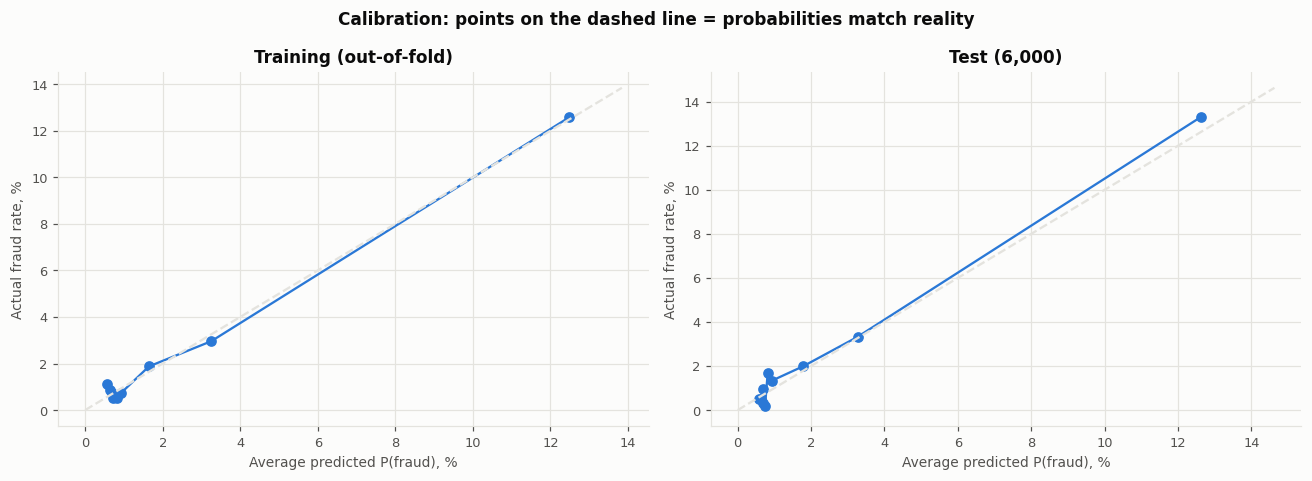

,Predicted,Actual,Transactions,Frauds
1,0.56%,1.12%,2400,27
2,0.63%,0.88%,2400,21
3,0.68%,0.75%,2400,18
4,0.72%,0.50%,2400,12
5,0.76%,0.58%,2400,14
6,0.83%,0.50%,2400,12
7,0.94%,0.75%,2400,18
8,1.64%,1.88%,2400,45
9,3.25%,2.96%,2400,71
10,12.49%,12.58%,2400,302


In [13]:
def calibration_table(p, y):
    """Average predicted P(fraud) and actual fraud rate in ten equal-sized risk groups."""
    g = pd.qcut(p, 10, labels=False, duplicates="drop")
    t = pd.DataFrame({"Predicted": pd.Series(p).groupby(g).mean(), "Actual": pd.Series(y).groupby(g).mean(),
                      "Transactions": pd.Series(y).groupby(g).size(), "Frauds": pd.Series(y).groupby(g).sum()})
    t.index = [f"{i + 1}" for i in range(len(t))]
    return t


cal_train, cal_test = calibration_table(oof_chosen, y_train), calibration_table(p_test, y_test)
brier = pd.DataFrame({"Chosen model": [brier_score_loss(y_train, oof_chosen), brier_score_loss(y_test, p_test)],
                      "Always the fraud rate": [brier_score_loss(y_train, np.full(len(y_train), y_train.mean())),
                                                brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))]},
                     index=["Training (out-of-fold)", "Test"])
display(brier.style.format("{:.5f}"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, t, title in [(axes[0], cal_train, "Training (out-of-fold)"), (axes[1], cal_test, "Test (6,000)")]:
    ax.plot(t.Predicted * 100, t.Actual * 100, "o-", color=BLUE)
    lim = max(t.Predicted.max(), t.Actual.max()) * 100 * 1.1
    ax.plot([0, lim], [0, lim], color=GRID, ls="--")
    ax.set_xlabel("Average predicted P(fraud), %"); ax.set_ylabel("Actual fraud rate, %"); ax.set_title(title)
fig.suptitle("Calibration: points on the dashed line = probabilities match reality", fontsize=11, fontweight="bold")
fig.tight_layout(); save_chart(fig, "04_calibration"); plt.show()
cal_train.style.format({"Predicted": "{:.2%}", "Actual": "{:.2%}"})

## 10. Explaining the model (decision M3-14)

- **What the model relies on:** for a logistic-type model, its weights and odds ratios; for a tree model, SHAP importances.
- **SHAP** splits each transaction's predicted risk into a push from each input. The pushes add up to the prediction (on the log-odds scale). Positive = pushes towards fraud.
- **Check against Task 1:** the model should rely mostly on the columns Task 1 found strong (amount and the amount ratio).
- **Three example test transactions**, explained in ₹: the lowest, the middle and the highest P(fraud).

Share of the model's reliance on the two strong Task 1 columns (amount, amount ratio): 88%
ln_Amount_Ratio                  0.534
ln_Amount                        0.348
Transaction_Type_Transfer        0.068
ln_Historical_Avg_Transaction    0.045
Transaction_Type_Withdrawal      0.005


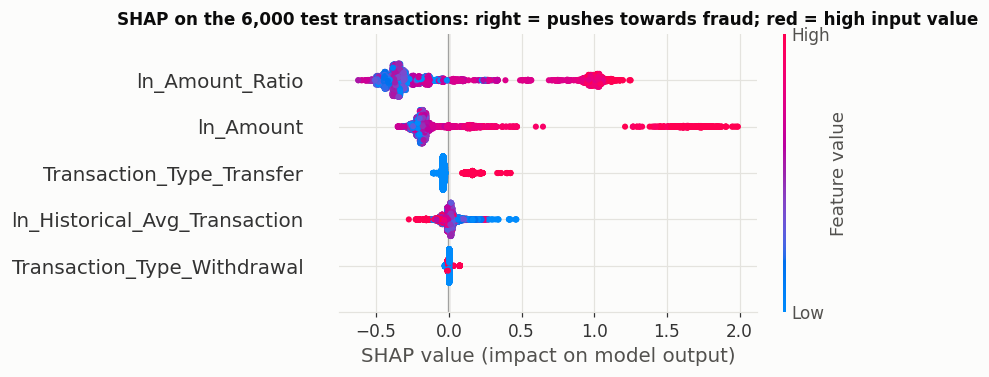

In [14]:
Xc_train = X_train[CHOSEN[1]] if CHOSEN[0] != "Amount alone" else pd.DataFrame(X_amount_train, columns=["ln_Amount"])
Xc_test = X_test[CHOSEN[1]] if CHOSEN[0] != "Amount alone" else pd.DataFrame(X_amount_test, columns=["ln_Amount"])
est = final.best_estimator_ if hasattr(final, "best_estimator_") else final
IS_LINEAR = isinstance(est, Pipeline)

if IS_LINEAR:
    lin = est.named_steps["model"]
    Z_train = pd.DataFrame(est.named_steps["scale"].transform(Xc_train), columns=Xc_train.columns)
    Z_test = pd.DataFrame(est.named_steps["scale"].transform(Xc_test), columns=Xc_test.columns)
    weights = pd.DataFrame({"Weight b (per 1 standard deviation)": lin.coef_[0], "Odds ratio e^b": np.exp(lin.coef_[0])},
                           index=Xc_train.columns).sort_values("Weight b (per 1 standard deviation)", key=abs, ascending=False)
    display(weights.style.format("{:.3f}"))
    explainer = shap.LinearExplainer(lin, Z_train)
    sv = explainer(Z_test)
else:
    explainer = shap.TreeExplainer(est)
    sv = explainer(Xc_test)
    if sv.values.ndim == 3:                                   # some tree models return one set per class
        sv = sv[:, :, 1]

imp = pd.Series(np.abs(sv.values).mean(axis=0), index=Xc_test.columns).sort_values(ascending=False)
imp_share = imp / imp.sum()
strong_share = imp_share[[c for c in imp_share.index if c in ("ln_Amount", "ln_Amount_Ratio")]].sum()
print(f"Share of the model's reliance on the two strong Task 1 columns (amount, amount ratio): {strong_share:.0%}")
print(imp_share.head(10).round(3).to_string())

fig = plt.figure(figsize=(9, 5))
np.random.seed(SEED)                        # SHAP places overlapping dots at random: fixed so reruns draw the same chart
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("SHAP on the 6,000 test transactions: right = pushes towards fraud; red = high input value")
plt.tight_layout(); save_chart(plt.gcf(), "05_shap_summary"); plt.show()

In [15]:
# Three example test transactions: lowest, middle and highest P(fraud).
order = np.argsort(p_test)
picks = {"Lowest P(fraud)": order[0], "Middle P(fraud)": order[len(order) // 2], "Highest P(fraud)": order[-1]}
ex_rows = []
for label, i in picks.items():
    pushes = pd.Series(sv.values[i], index=Xc_test.columns).sort_values(key=abs, ascending=False)
    ex_rows.append({"Example": label, "Transaction_ID": test.Transaction_ID[i], "Amount (₹)": test.Amount[i],
                    "Usual amount (₹)": test.Historical_Avg_Transaction[i], "Amount ÷ usual": test.Amount_Ratio[i],
                    "Type": str(test.Transaction_Type[i]), "P(fraud)": p_test[i],
                    "Expected ₹ loss (P × amount)": p_test[i] * test.Amount[i],
                    "Biggest pushes": "; ".join(f"{k} {v:+.2f}" for k, v in pushes.head(3).items()),
                    "Actually fraud": "Yes" if y_test[i] == 1 else "No"})
examples = pd.DataFrame(ex_rows)
examples.style.format({"Amount (₹)": "₹{:,.0f}", "Usual amount (₹)": "₹{:,.0f}", "Amount ÷ usual": "{:.2f}",
                       "P(fraud)": "{:.2%}", "Expected ₹ loss (P × amount)": "₹{:,.0f}"}).hide(axis="index")

Example,Transaction_ID,Amount (₹),Usual amount (₹),Amount ÷ usual,Type,P(fraud),Expected ₹ loss (P × amount),Biggest pushes,Actually fraud
Lowest P(fraud),5029222,"₹1,853","₹23,527",0.08,Withdrawal,0.50%,₹9,ln_Amount_Ratio -0.49; ln_Amount -0.19; ln_Historical_Avg_Transaction -0.16,No
Middle P(fraud),5027041,"₹9,084","₹6,750",1.35,Transfer,0.78%,₹70,ln_Amount_Ratio -0.39; ln_Amount -0.17; Transaction_Type_Transfer +0.14,No
Highest P(fraud),5025361,"₹48,919",₹872,56.13,Withdrawal,29.56%,"₹14,459",ln_Amount +1.99; ln_Amount_Ratio +1.15; ln_Historical_Avg_Transaction +0.46,No


## 11. What the results say

### Leakage checks (step 1): all pass
- Fraud_Flag is in no input; every training transaction comes before every test transaction; each customer's first transaction shows no device or city change.
- The usual amount doesn't contain the current one: correlation +0.003 overall, −0.055 among frauds.

### The ML case: which model, and how much it adds (steps 4–6)

| Set-up (25 rounds) | PR-AUC | ROC-AUC | Training-vs-unseen gap | Verdict |
| --- | --- | --- | --- | --- |
| Amount alone (benchmark) | 0.116 | 0.788 | 0.000 | Beaten beyond chance |
| Logistic / lasso (either input set) | 0.125–0.127 | 0.796–0.801 | 0.001–0.009 | Below the best beyond chance |
| Decision tree | 0.108–0.114 | 0.784–0.790 | 0.03–0.04 | Below the best; no better than amount alone |
| Random forest | 0.124–0.134 | 0.779–0.790 | **0.13–0.14** | **Ruled out: overfits** (gap above 0.10) |
| **LightGBM, strong + weak inputs** | **0.132** | 0.794 | 0.056 | **Chosen** |
| LightGBM, all columns | 0.135 (best) | 0.793 | 0.075 | Within chance of the chosen one; more inputs not justified |

- **The rule, step by step:** the forests are ruled out for overfitting. The best PR-AUC is LightGBM on all columns (0.135). The simplest set-up within chance of it is **LightGBM on the strong + weak inputs** (difference +0.004, 95% range −0.002 to +0.009). Logistic and lasso fall below the best beyond chance (about −0.009).
- **The chosen model** is small: 100 trees of 4 leaves each, tuned inside the rounds. It uses five inputs: amount, amount ratio, usual amount and transaction type.
- **It beats amount alone beyond chance in cross-validation:** PR-AUC +0.016 (95% range +0.010 to +0.022), better in 22 of 25 rounds.
- **The extra eight columns add nothing:** LightGBM on all columns is within chance of the strong + weak set. Task 1's verdicts hold in combination too.

### The final test: 6,000 later transactions (May–Aug 2026), used once (step 8)

| Measure | Chosen model | Amount alone | Difference (95% range) |
| --- | --- | --- | --- |
| PR-AUC | 0.124 | 0.103 | +0.021 (−0.000 to +0.050) |
| ROC-AUC | 0.815 | 0.787 | **+0.028 (+0.004 to +0.054)** |
| Brier (lower is better) | 0.0218 | 0.0226 | **−0.0007 (−0.0012 to −0.0004)** |
| Frauds caught, top 5% | 33.3% | 28.5% | +4.9 points (−0.8 to +11.0) |
| Fraud ₹ caught, top 5% | 55.2% | 56.1% | −0.9 points (−11.3 to +9.1) |

- **The same direction as cross-validation.** The model ranks fraud better (ROC-AUC gain proven) and gives better probabilities (Brier gain proven). The PR-AUC gain only just touches zero on 144 test frauds.
- **Accuracy is useless, as expected:** at a 50% cut-off the model flags nothing, and scores 97.60%, the same as calling everything honest.

### The finance case: what investigating catches, in ₹ (step 7)

Out-of-fold, 24,000 training transactions. ₹6.71 lakh of fraud passes through every 1,000 transactions.

| Investigate the top… | Ranking | Frauds caught | Fraud ₹ caught | Per 1,000 transactions: fraud ₹ caught | ₹ per investigation |
| --- | --- | --- | --- | --- | --- |
| 1% | Chosen model | **8.9%** | 16.4% | ₹1.10 lakh | ₹11,021 |
| | Amount alone | 6.1% | **22.3%** | **₹1.50 lakh** | **₹14,982** |
| 5% | Chosen model | 35.7% | 59.5% | ₹3.99 lakh | ₹7,979 |
| | Amount alone | 34.1% | 64.9% | ₹4.36 lakh | ₹8,711 |
| | Chosen model × amount | **37.2%** | **67.6%** | **₹4.53 lakh** | **₹9,068** |
| 10% | All three | 55–56% | 84–85% | ₹5.65–5.71 lakh | about ₹5,700 |

**The model's extra catch over amount alone (average of the 25 rounds; the table above pools all out-of-fold scores, so its gaps differ slightly):**

| Budget | Extra frauds caught | Extra fraud ₹ caught |
| --- | --- | --- |
| 1% | **+3.1 points (+2.0 to +4.3)** | **−5.6 points (−8.5 to −2.8)** |
| 5% | +1.7 points (+0.4 to +3.1) | −6.0 points (−8.9 to −3.1) |
| 10% | +0.4 points (−0.4 to +1.2) | −0.7 points (−1.2 to −0.1) |

- **The model finds more frauds but fewer fraud rupees.** Beyond chance at tight budgets, it puts medium-sized, very unusual transactions (for example, 56 times the customer's usual amount) ahead of the largest ones. The largest transactions carry more ₹, even though a smaller share of them is fraud.
- **Combining both gives the best of each:** ranking by **P(fraud) × amount** (expected ₹ loss) catches the most frauds *and* the most ₹ at the 5% budget. Whether Task 4 uses it is decided there.
- **By 10% of transactions, every sensible ranking catches about 85% of the fraud ₹.** The large frauds are found by any of them; what remains is the ordinary-looking frauds.

### Calibration, reported (step 9)
- **In the riskiest tenth, the probabilities match reality:** 12.5% predicted vs 12.6% actual on training, and 12.6% vs 13.3% on test.
- **In the safest tenths, predictions sit near 0.6%**, against actual rates of 0.2–1.7%, which bounce around with few frauds per group.
- Brier beats always predicting the fraud rate on both sets.
- How Task 4 uses the probabilities, and any pass lines, are decided there (M3-13).

### What the model relies on (step 10)
- **88% of its reliance is on the two strong Task 1 columns:** amount ratio (53%) and amount (35%). Transfers add 7%, the usual amount 5%.
- **The highest-scored test transaction:** ₹48,919, 56 times the customer's usual ₹872. P(fraud) is 30%, so the expected loss is about ₹14,500. **It was not fraud.** Even the most suspicious transactions are honest 7 times in 10. A transaction can be flagged as suspicious, not proven fraud.

### What goes to Tasks 3 and 4
- `outputs/task2/FINAL_M3_T2_fraud_scores.csv`: P(fraud) for every transaction (out-of-fold for training, final model for test), with the amount-alone score alongside.
- `chosen_model.joblib`: LightGBM, 100 trees of 4 leaves, on amount, amount ratio, usual amount and transaction type.
- **For Task 3 to compare:** catch curves in frauds and in ₹, on the same 6,000 test transactions.
- **For Task 4 to decide:**
  - whether a missed fraud costs a flat ₹10,000 or its actual amount;
  - whether the threshold is set on P(fraud), on P(fraud) × amount, or found by sweeping costs.

## 12. Save the outputs (decision M3-14)

- **`FINAL_M3_T2_fraud_scores.csv`: each transaction's score, for Tasks 3 and 4.** Transaction_ID, Set (training / test), Fraud_Flag, Amount, P_fraud (chosen model: out-of-fold for training transactions, final model for test), P_benchmark (amount alone, same basis).
- `chosen_model.joblib` and `chosen_model.json`: the fitted model and its settings, to score new transactions.
- `cv_summary.csv`: the 25-round comparison of every set-up (the key evidence table).
- The charts above, and `key_numbers.json`. Every other table is shown above and in the report (decision M3-16).

In [16]:
scores = pd.concat([
    pd.DataFrame({"Transaction_ID": train.Transaction_ID, "Set": "train (out-of-fold)", "Fraud_Flag": y_train,
                  "Amount": train.Amount, "P_fraud": oof_chosen, "P_benchmark": oof_bench}),
    pd.DataFrame({"Transaction_ID": test.Transaction_ID, "Set": "test", "Fraud_Flag": y_test,
                  "Amount": test.Amount, "P_fraud": p_test, "P_benchmark": p_test_bench}),
]).reset_index(drop=True)
assert scores.Transaction_ID.is_unique and len(scores) == len(tx) and scores.notna().all().all()
save_table(scores.round(6), "FINAL_M3_T2_fraud_scores")

for k in [k for k in getattr(final, "cv_results_", {}) if k.endswith("_time")]:
    final.cv_results_[k] = np.zeros_like(final.cv_results_[k])    # fit/score times differ every run; zeroed so the saved model is repeatable
if hasattr(final, "refit_time_"):
    final.refit_time_ = 0.0
joblib.dump(final, OUT_DIR / "chosen_model.joblib")
settings = {"model": CHOSEN[0], "inputs": CHOSEN[1], "columns": INPUT_SETS.get(CHOSEN[1], ["Amount"]),
            "trained_on": "24,000 training transactions (Jan 2025 – Apr 2026)", "seed": SEED}
if hasattr(final, "best_params_"):
    settings["tuned"] = {k: (v.item() if hasattr(v, "item") else v) for k, v in final.best_params_.items()}
(OUT_DIR / "chosen_model.json").write_text(json.dumps(settings, indent=1), encoding="utf-8")


def r4(v):
    return round(float(v), 4)


key = {
    "chosen": list(CHOSEN), "best": list(BEST), "ruled_out": [list(k) for k in RULED_OUT],
    "cv": {f"{m} [{s}]": {"PR_AUC": r4(summary.loc[(m, s), "PR_AUC"]), "ROC_AUC": r4(summary.loc[(m, s), "ROC_AUC"]),
                          "Gap": r4(summary.loc[(m, s), "Gap"])} for m, s in summary.index},
    "chosen_vs_amount_pr_auc": [r4(v) for v in VS_BENCH[:3]] + [VS_BENCH[3]],
    "test": {c: {k: r4(v) for k, v in point[c].items()} for c in point.columns},
    "test_diff_ranges": {k: [r4(test_tbl.loc[k, "Difference"]), r4(test_tbl.loc[k, "Difference 95% low"]),
                             r4(test_tbl.loc[k, "Difference 95% high"])] for k in test_tbl.index},
    "strong_share_shap": r4(strong_share),
}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to module_03_fraud_detection/outputs/task2
['01_cv_comparison.png', '02_overfitting_check.png', '03_catch_curves.png', '04_calibration.png', '05_shap_summary.png', 'FINAL_M3_T2_fraud_scores.csv', 'chosen_model.joblib', 'chosen_model.json', 'cv_summary.csv', 'key_numbers.json']
